In [6]:
import re, numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

FEAT_DIR   = Path("Dataset/ekstraksi_fitur_v2")
TRAIN_ASLI = FEAT_DIR / "fitur_train_asli.csv"
TRAIN_AUG  = FEAT_DIR / "fitur_train_aug.csv"
TEST_CSV   = FEAT_DIR / "fitur_test_murni.csv"    # dibuat dengan fungsi ekstraksi yang SAMA
LABEL_COL, FILE_COL = "label", "file"

assert TEST_CSV.exists(), f"{TEST_CSV} belum ada: ekstrak fitur test_murni dulu di ekstraksi_fitur.ipynb"
df_asli, df_aug, df_test = pd.read_csv(TRAIN_ASLI), pd.read_csv(TRAIN_AUG), pd.read_csv(TEST_CSV)
print(df_asli.shape, df_aug.shape, df_test.shape)
for nama, d in [("train_asli", df_asli), ("train_aug", df_aug), ("test_murni", df_test)]:
    print(nama, d[LABEL_COL].value_counts().to_dict())
assert set(df_test[LABEL_COL]) <= set(df_asli[LABEL_COL]), "label di test_murni tidak cocok dengan train (cek ejaan nama kelas)"

(413, 26) (822, 26) (107, 26)
train_asli {'yelowwiss': 256, 'Daunsehat': 115, 'Leafcurl': 42}
train_aug {'Daunsehat': 293, 'Leafcurl': 273, 'yelowwiss': 256}
test_murni {'yelowwiss': 68, 'Daunsehat': 28, 'Leafcurl': 11}


In [7]:
FITUR = list(df_asli.select_dtypes(include=[np.number]).columns)
assert FITUR == list(df_aug.select_dtypes(include=[np.number]).columns), "kolom fitur train_asli dan train_aug beda"
assert all(c in df_test.columns for c in FITUR), "kolom fitur test_murni tidak lengkap"
print("jumlah fitur:", len(FITUR))

Xa, ya = df_asli[FITUR], df_asli[LABEL_COL].astype(str)
Xg, yg = df_aug[FITUR],  df_aug[LABEL_COL].astype(str)
Xt, yt = df_test[FITUR], df_test[LABEL_COL].astype(str)

jumlah fitur: 23


In [8]:
def asal(nama):
    s = Path(str(nama)).stem
    s = re.sub(r"_d\d+$", "", s)            # buang _d1, _d2 (hasil segmentasi)
    s = re.sub(r"^(aug_\d+_)+", "", s)      # buang awalan augmentasi: aug_001_, aug_002_, ...
    return s

ga = df_asli[FILE_COL].map(asal)
gg = df_aug[FILE_COL].map(asal)
print(f"{gg.isin(set(ga)).mean():.1%} baris train_aug punya foto asal di train_asli")

99.3% baris train_aug punya foto asal di train_asli


In [9]:
pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC(class_weight="balanced"))])
grid = {
    "svm__kernel": ["rbf", "linear"],
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.1, 0.01, 0.001],      # diabaikan oleh kernel linear
}

def train(X, y, groups, name):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X, y, groups=groups)
    print(f"[{name}] terbaik: {gs.best_params_} | f1_macro CV: {gs.best_score_:.4f}")
    return gs.best_estimator_

model_A = train(Xa, ya, ga, "A: train_asli")
model_B = train(Xg, yg, gg, "B: train_aug")

[A: train_asli] terbaik: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'} | f1_macro CV: 0.9238
[B: train_aug] terbaik: {'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'} | f1_macro CV: 0.9515


 A: train_asli
              precision    recall  f1-score   support

   Daunsehat      1.000     1.000     1.000        28
    Leafcurl      0.917     1.000     0.957        11
   yelowwiss      1.000     0.985     0.993        68

    accuracy                          0.991       107
   macro avg      0.972     0.995     0.983       107
weighted avg      0.991     0.991     0.991       107



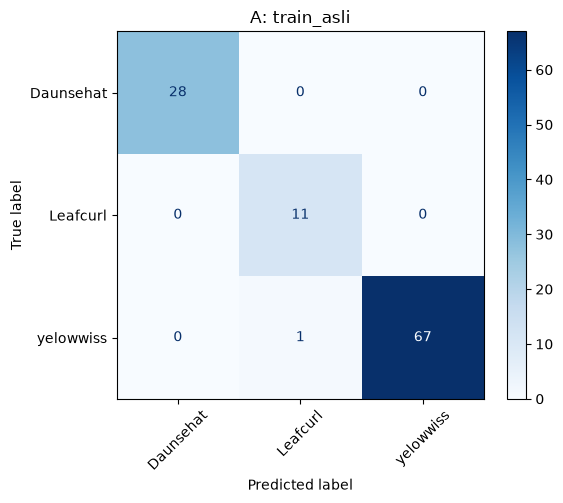

 B: train_aug
              precision    recall  f1-score   support

   Daunsehat      1.000     1.000     1.000        28
    Leafcurl      1.000     0.909     0.952        11
   yelowwiss      0.986     1.000     0.993        68

    accuracy                          0.991       107
   macro avg      0.995     0.970     0.982       107
weighted avg      0.991     0.991     0.990       107



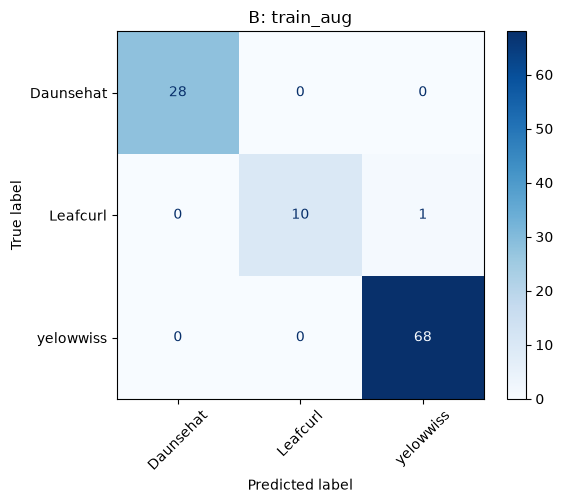

,akurasi,f1_macro
A: train_asli,0.9907,0.9830
B: train_aug,0.9907,0.9817


In [10]:
results = {}
for name, m in [("A: train_asli", model_A), ("B: train_aug", model_B)]:
    pred = m.predict(Xt)
    results[name] = (accuracy_score(yt, pred), f1_score(yt, pred, average="macro"))
    print("="*60, "\n", name)
    print(classification_report(yt, pred, digits=3))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(confusion_matrix(yt, pred, labels=m.classes_), display_labels=m.classes_).plot(ax=ax, cmap="Blues", xticks_rotation=45)
    ax.set_title(name); plt.tight_layout(); plt.show()

pd.DataFrame(results, index=["akurasi", "f1_macro"]).T.round(4)

In [11]:
best = max(results, key=lambda k: results[k][1])
print("model terbaik (f1_macro):", best)
joblib.dump({"model": model_A if best.startswith("A") else model_B, "fitur": FITUR}, "model_svm_daun_cabai.joblib")
print("tersimpan: model_svm_daun_cabai.joblib")

model terbaik (f1_macro): A: train_asli
tersimpan: model_svm_daun_cabai.joblib
